# UPMaBoSS: sensitivity to the update time

This notebook complements the [UPMaBoSS cell fate notebook](CellFateModel_uppmaboss.ipynb) of the
[MaBoSS website](https://maboss.curie.fr).

With UPMaBoSS, the population is updated at regular intervals: the update time is set by `max_time` in the
configuration file, and the number of updates by `steps` in the update file. This update time cannot be set
from biological considerations: it should be smaller than the first transient effect, and the sensitivity of the
results to its value should be studied. We do so for the cell fate model, with a transient TNF activation and
without TNF.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `CellFateModel_uppmaboss.bnd`,
`CellFateModel_uppmaboss.cfg` and `CellFateModel_uppmaboss.upp`, in the same folder as this notebook.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


In [2]:
bnd_file = "CellFateModel_uppmaboss.bnd"
cfg_file = "CellFateModel_uppmaboss.cfg"
upp_file = "CellFateModel_uppmaboss.upp"

model_WT = maboss.load(bnd_file, cfg_file)
model_noTNF = model_WT.copy()
model_noTNF.network.set_istate("TNF", [1, 0])

max_time = float(model_WT.param["max_time"])
time_tick = float(model_WT.param["time_tick"])

## First transient effects

We first run MaBoSS simulations over 48 hours, without taking into account cell death and division, to find the
first transient effects.

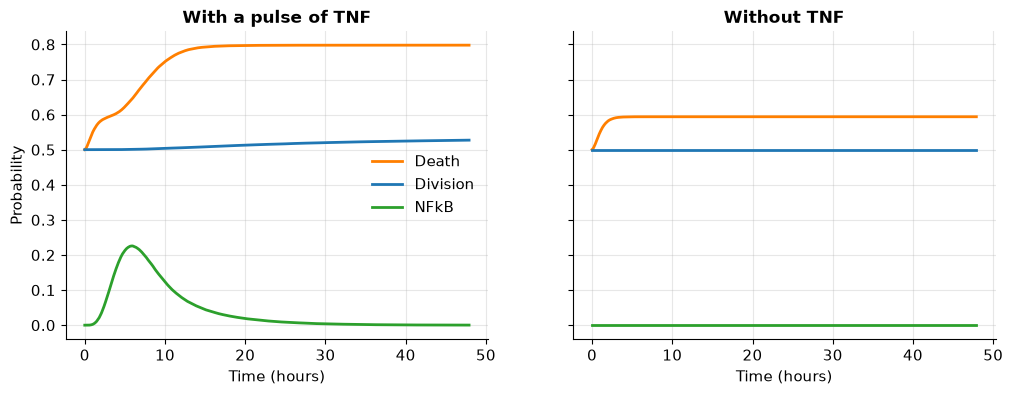

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, model) in zip(axes, [("With a pulse of TNF", model_WT), ("Without TNF", model_noTNF)]):
    model_48h = maboss.copy_and_update_parameters(model, {"max_time": 48})
    model_48h.network.set_output(("Death", "Division", "NFkB"))
    nodes = model_48h.run().get_nodes_probtraj()
    for node in ["Death", "Division", "NFkB"]:
        ax.plot(nodes.index, nodes[node], label=node)
    ax.set_xlabel("Time (hours)")
    ax.set_title(name)
axes[0].set_ylabel("Probability")
axes[0].legend()
save(fig, "upmaboss_timestep_maboss")

With TNF, the first local extremum occurs at t = 1 hour. Without TNF, the asymptotic behaviour is reached very
fast, and the probabilities vary very little (NFκB stays inactive). In both cases, the update time should be at
most 1 hour.

## UPMaBoSS simulations with different update times

We run UPMaBoSS with update times of 1, 1/2, 1/3 and 1/4 hour, keeping a total time of 48 hours.

In [4]:
def run_with_update_time(model, divisor, name):
    """Population ratios (indexed by time) for an update time of max_time / divisor, over 48 hours."""
    params = {"max_time": max_time / divisor, "time_tick": time_tick / divisor}
    upp = maboss.UpdatePopulation(maboss.copy_and_update_parameters(model, params), upp_file)
    upp.setStepNumber(48 * divisor)
    ratios = upp.run(f"{name}_R{divisor}").get_population_ratios(f"Update time = 1/{divisor} h" if divisor > 1 else "Update time = 1 h")
    ratios.index = ratios.index.astype(float)  # already indexed by time
    return ratios

divisors = [1, 2, 3, 4]
results = {
    "With a pulse of TNF": [run_with_update_time(model_WT, d, "WT") for d in divisors],
    "Without TNF": [run_with_update_time(model_noTNF, d, "noTNF") for d in divisors],
}

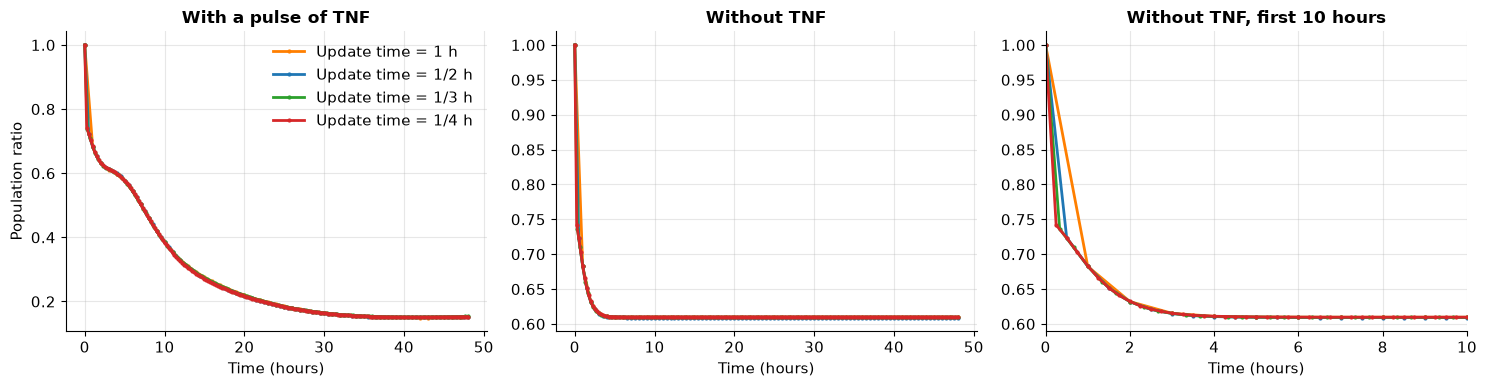

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
panels = [("With a pulse of TNF", None), ("Without TNF", None), ("Without TNF", 10)]
for ax, (name, xmax) in zip(axes, panels):
    for ratios in results[name]:
        ax.plot(ratios.index, ratios.values, marker="o", markersize=2, label=ratios.name)
    ax.set_xlabel("Time (hours)")
    ax.set_title(name + (f", first {xmax} hours" if xmax else ""))
    if xmax:
        ax.set_xlim(0, xmax)
axes[0].set_ylabel("Population ratio")
axes[0].legend()
fig.tight_layout()
save(fig, "upmaboss_timestep")

With or without TNF, the population dynamics are robust: the different update times give almost identical
population ratios, the shortest update times only resolving more finely the first hour.